MAE: 8901.29074396485 MSE: 114170418.45453805 R2: 0.8062934622232141


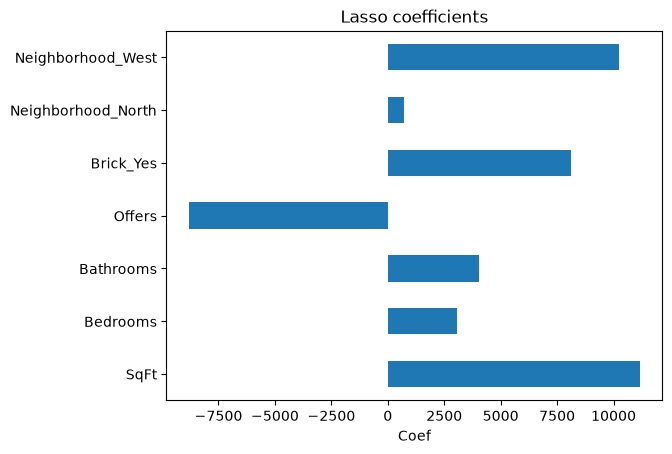

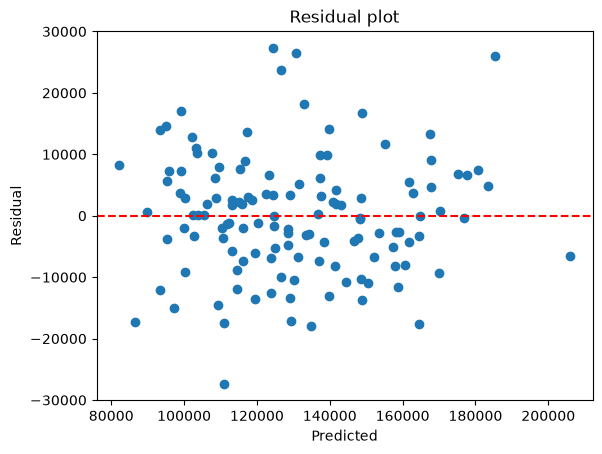

In [1]:
# ===================== REVISION / ONE-SHOT: REGRESSION =====================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1) Load, encode text columns, X / y
df = pd.read_csv("datasets/house-prices.csv")
X = pd.get_dummies(df.drop(["Home", "Price"], axis=1), drop_first=True, dtype=int)   # one-hot categoricals
y = df["Price"]

# 2) Split + fit + metrics
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = LinearRegression().fit(X_train, y_train)
y_pred = model.predict(X_test)
print("MAE:", mean_absolute_error(y_test, y_pred), "MSE:", mean_squared_error(y_test, y_pred), "R2:", r2_score(y_test, y_pred))

# 3) Polynomial: X_poly = PolynomialFeatures(degree=2).fit_transform(X_single_col)
# 4) Lasso / Ridge: scale first, then Lasso(alpha=...) / Ridge(alpha=...); coef_ bar plot
Xs = StandardScaler().fit_transform(X)
lasso = Lasso(alpha=1.0).fit(Xs, y)
pd.Series(lasso.coef_, index=X.columns).plot(kind="barh"); plt.title("Lasso coefficients"); plt.xlabel("Coef"); plt.show()

# 5) Residual plot: residual = actual - predicted, should scatter randomly around 0
y_hat = lasso.predict(Xs)
plt.scatter(y_hat, y - y_hat); plt.axhline(0, color="red", linestyle="--")
plt.title("Residual plot"); plt.xlabel("Predicted"); plt.ylabel("Residual"); plt.show()

# 6) PCA + regression: scale -> PCA(n_components=k) -> LinearRegression

# ---------------- VIVA NOTES ----------------
# Linear regression minimizes sum of squared errors (OLS): y = b0 + b1*x1 + ...
# MAE = mean |error|, MSE = mean error^2 (punishes big errors), R2 = share of variance explained (1 is best).
# Ridge = L2 penalty (shrinks coefs), Lasso = L1 penalty (can make coefs exactly 0 -> feature selection).
# alpha = penalty strength; scale features before Ridge/Lasso so the penalty is fair.
# Gradient descent: w = w - lr * dLoss/dw, repeated for many epochs; scale x for fast convergence.
# Residual plot: random cloud around 0 = good fit; curve / funnel = missing non-linearity / unequal variance.

### Q39

develop a linear regression model to predict house prices based on various features. You will use a dataset that contains information about houses, including features such as the number of bedrooms, square footage, and location. You will evaluate the model's performance using metrics such as Mean Absolute Error (MAE), Mean Squared Error (MSE), and R-squared. Show performance of same model when PCA reduced data set is used.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [3]:
# Load house data (Bedrooms, SqFt, Neighborhood = location, Price = target)
df = pd.read_csv("datasets/house-prices.csv")
print(df.head())
print(df.dtypes)

   Home   Price  SqFt  Bedrooms  Bathrooms  Offers Brick Neighborhood
0     1  114300  1790         2          2       2    No         East
1     2  114200  2030         4          2       3    No         East
2     3  114800  1740         3          2       1    No         East
3     4   94700  1980         3          2       3    No         East
4     5  119800  2130         3          3       3    No         East
Home            int64
Price           int64
SqFt            int64
Bedrooms        int64
Bathrooms       int64
Offers          int64
Brick             str
Neighborhood      str
dtype: object


In [4]:
# One-hot encode text columns (Brick, Neighborhood), drop ID
X = pd.get_dummies(df.drop(["Home", "Price"], axis=1), drop_first=True, dtype=int)
y = df["Price"]
print(X.head())
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

   SqFt  Bedrooms  Bathrooms  Offers  Brick_Yes  Neighborhood_North  \
0  1790         2          2       2          0                   0   
1  2030         4          2       3          0                   0   
2  1740         3          2       1          0                   0   
3  1980         3          2       3          0                   0   
4  2130         3          3       3          0                   0   

   Neighborhood_West  
0                  0  
1                  0  
2                  0  
3                  0  
4                  0  


In [5]:
# Model 1: linear regression on all features
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
mae1, mse1, r21 = mean_absolute_error(y_test, y_pred), mean_squared_error(y_test, y_pred), r2_score(y_test, y_pred)
print(f"Original -> MAE: {mae1:.0f}, MSE: {mse1:.0f}, R2: {r21:.4f}")

Original -> MAE: 8901, MSE: 114170418, R2: 0.8063


In [6]:
# Model 2: same model on PCA reduced data (scale -> PCA with 4 components)
sc = StandardScaler()
X_train_s = sc.fit_transform(X_train)
X_test_s = sc.transform(X_test)
pca = PCA(n_components=4)
X_train_pca = pca.fit_transform(X_train_s)
X_test_pca = pca.transform(X_test_s)
print("Features:", X_train.shape[1], "-> PCA components:", X_train_pca.shape[1])
print("Variance kept:", round(pca.explained_variance_ratio_.sum(), 3))

model_pca = LinearRegression()
model_pca.fit(X_train_pca, y_train)
y_pred_pca = model_pca.predict(X_test_pca)
mae2, mse2, r22 = mean_absolute_error(y_test, y_pred_pca), mean_squared_error(y_test, y_pred_pca), r2_score(y_test, y_pred_pca)
print(f"PCA      -> MAE: {mae2:.0f}, MSE: {mse2:.0f}, R2: {r22:.4f}")

Features: 7 -> PCA components: 4
Variance kept: 0.819
PCA      -> MAE: 9733, MSE: 172086976, R2: 0.7080


         Original           PCA
MAE  8.901291e+03  9.733042e+03
MSE  1.141704e+08  1.720870e+08
R2   8.060000e-01  7.080000e-01


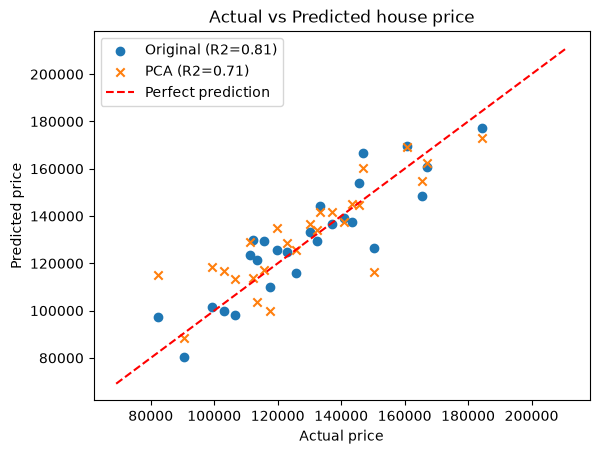

In [7]:
# Compare
print(pd.DataFrame({"Original": [mae1, mse1, r21], "PCA": [mae2, mse2, r22]}, index=["MAE", "MSE", "R2"]).round(3))
plt.scatter(y_test, y_pred, label=f"Original (R2={r21:.2f})")
plt.scatter(y_test, y_pred_pca, label=f"PCA (R2={r22:.2f})", marker="x")
plt.plot([y.min(), y.max()], [y.min(), y.max()], "r--", label="Perfect prediction")
plt.title("Actual vs Predicted house price")
plt.xlabel("Actual price")
plt.ylabel("Predicted price")
plt.legend()
plt.show()

### Q40

apply Principal Component Analysis (PCA) to a house price prediction dataset to reduce its dimensionality and then use a regression model to predict house prices. You will evaluate the model's performance using metrics such as Mean Absolute Error (MAE), Mean Squared Error (MSE), and R-squared (R²).

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [9]:
# Load, encode, split, scale
df = pd.read_csv("datasets/house-prices.csv")
X = pd.get_dummies(df.drop(["Home", "Price"], axis=1), drop_first=True, dtype=int)
y = df["Price"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)
print("Features:", X.shape[1])

Features: 7


Cumulative variance: [0.374 0.603 0.736 0.819 0.895 0.957 1.   ]


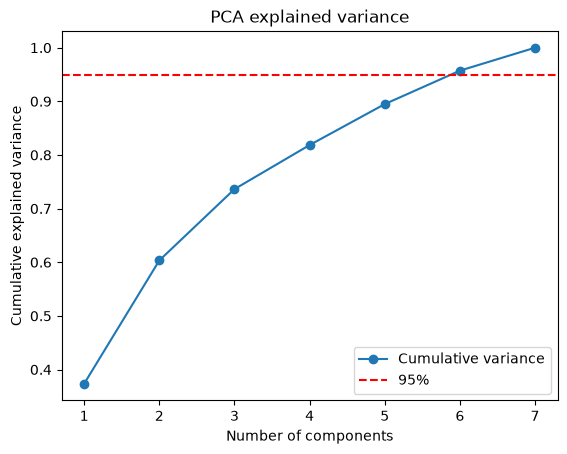

In [10]:
# Explained variance to choose number of components
pca_all = PCA().fit(X_train)
cum = np.cumsum(pca_all.explained_variance_ratio_)
print("Cumulative variance:", cum.round(3))
plt.plot(range(1, len(cum) + 1), cum, marker="o", label="Cumulative variance")
plt.axhline(0.95, color="red", linestyle="--", label="95%")
plt.title("PCA explained variance")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.legend()
plt.show()

In [11]:
# PCA keeping 95% variance, then linear regression
pca = PCA(n_components=0.95)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)
print("Components kept:", pca.n_components_)

model = LinearRegression()
model.fit(X_train_pca, y_train)
y_pred = model.predict(X_test_pca)
print("MAE:", round(mean_absolute_error(y_test, y_pred), 2))
print("MSE:", round(mean_squared_error(y_test, y_pred), 2))
print("R2: ", round(r2_score(y_test, y_pred), 4))

Components kept: 6
MAE: 8686.05
MSE: 138516739.12
R2:  0.765


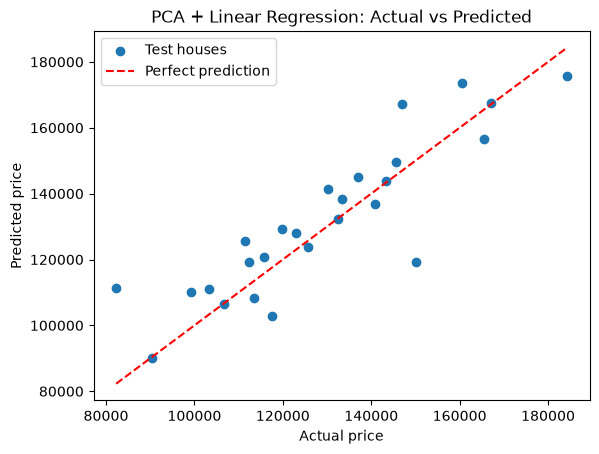

In [12]:
plt.scatter(y_test, y_pred, label="Test houses")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--", label="Perfect prediction")
plt.title("PCA + Linear Regression: Actual vs Predicted")
plt.xlabel("Actual price")
plt.ylabel("Predicted price")
plt.legend()
plt.show()

### Q51

Consider Salary.csv , with years_of_experience and salary. Write a python code for fitting best fit simple linear regression with independent variable years_of_experience and dependent variable salary. Use complete dataset to train model. Plot :fitted model along with trained data points , residual plot.

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

In [14]:
# Real columns are 'Years of Experience' and 'Salary'; drop the 2 empty rows
df = pd.read_csv("datasets/Salary.csv")
df = df.dropna(subset=["Years of Experience", "Salary"])
X = df[["Years of Experience"]]
y = df["Salary"]
print(df.shape)

(373, 6)


In [15]:
# Fit on complete dataset
model = LinearRegression()
model.fit(X, y)
y_pred = model.predict(X)
print("Slope:", round(model.coef_[0], 2), "| Intercept:", round(model.intercept_, 2))
print("R2:", round(r2_score(y, y_pred), 4))

Slope: 6844.51 | Intercept: 31921.22
R2: 0.8655


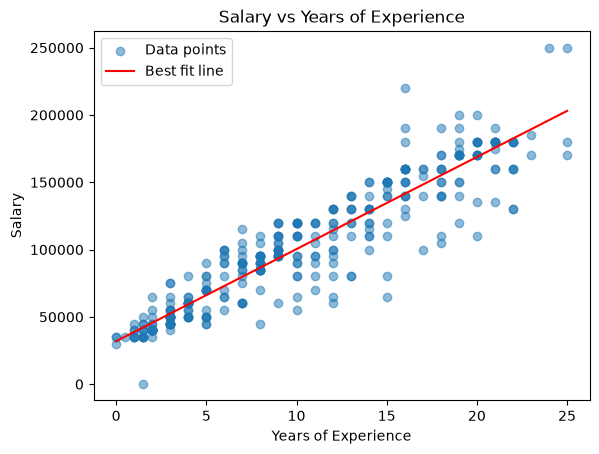

In [16]:
# Fitted line with data points
plt.scatter(X, y, alpha=0.5, label="Data points")
plt.plot(X.sort_values("Years of Experience"), model.predict(X.sort_values("Years of Experience")),
         color="red", label="Best fit line")
plt.title("Salary vs Years of Experience")
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.legend()
plt.show()

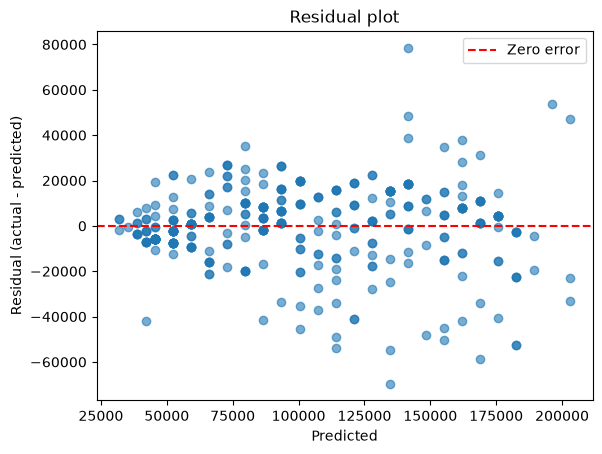

In [17]:
# Residual plot
residuals = y - y_pred
plt.scatter(y_pred, residuals, alpha=0.6)
plt.axhline(0, color="red", linestyle="--", label="Zero error")
plt.title("Residual plot")
plt.xlabel("Predicted")
plt.ylabel("Residual (actual - predicted)")
plt.legend()
plt.show()

### Q52

Consider a dataset HousePrices.csv with columns square_feet and price. Write a Python code to fit a polynomial regression model with square_feet as the independent variable and price as the dependent variable. Use the complete dataset to train the model. Plot the fitted polynomial model along with the trained data points and create a residual plot.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

In [ ]:
# If the exam file is house-prices.csv instead, use columns 'SqFt' and 'Price'
df = pd.read_csv("datasets/HousePrices.csv")
print(df.head())
X = df[["square_feet"]]
y = df["price"]

In [ ]:
# Polynomial features of degree 2: [1, x, x^2], then linear regression
poly = PolynomialFeatures(degree=2)
X_poly = poly.fit_transform(X)
model = LinearRegression()
model.fit(X_poly, y)
y_pred = model.predict(X_poly)
print("Coefficients:", model.coef_, "| Intercept:", round(model.intercept_, 2))
print("R2:", round(r2_score(y, y_pred), 4))

In [ ]:
# Fitted curve (sorted x for a smooth line)
x_line = np.linspace(X["square_feet"].min(), X["square_feet"].max(), 200).reshape(-1, 1)
y_line = model.predict(poly.transform(pd.DataFrame(x_line, columns=["square_feet"])))
plt.scatter(X, y, alpha=0.6, label="Data points")
plt.plot(x_line, y_line, color="red", label="Polynomial fit (degree 2)")
plt.title("Polynomial Regression: Price vs Square feet")
plt.xlabel("Square feet")
plt.ylabel("Price")
plt.legend()
plt.show()

In [ ]:
# Residual plot
residuals = y - y_pred
plt.scatter(y_pred, residuals, alpha=0.6)
plt.axhline(0, color="red", linestyle="--", label="Zero error")
plt.title("Residual plot")
plt.xlabel("Predicted")
plt.ylabel("Residual (actual - predicted)")
plt.legend()
plt.show()

### Q53

Consider a dataset CarPrices.csv with columns age, mileage, and price. Write a Python code to fit a multiple linear regression model with age and mileage as independent variables and price as the dependent variable. Use the complete dataset to train the model. Plot the actual prices against the predicted prices and create a residual plot.

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

In [24]:
# Real columns: age -> 'months_old', mileage -> 'km'
df = pd.read_csv("datasets/CarPrices.csv")
print(df.head())
X = df[["months_old", "km"]]
y = df["price"]

   months_old      km fuel_type  horsepower  metcolor  automatic  size_engine  \
0          73   97494    Petrol         110         1          0         1600   
1          48   89049    Petrol          97         1          0         1400   
2          40  161000    Diesel          69         1          0         1900   
3          37   38812    Petrol          97         0          0         1400   
4          55   33230    Petrol         110         0          0         1600   

   doors_num  weight  price  
0          5    1085  10950  
1          5    1060  13500  
2          3    1105  13950  
3          3    1025  13450  
4          3    1050  13500  


In [25]:
# Fit on complete dataset
model = LinearRegression()
model.fit(X, y)
y_pred = model.predict(X)
print("Coefficients:"); print(pd.Series(model.coef_, index=X.columns).round(4))
print("Intercept:", round(model.intercept_, 2))
print("R2:", round(r2_score(y, y_pred), 4))

Coefficients:
months_old   -153.3696
km             -0.0169
dtype: float64
Intercept: 22479.74
R2: 0.7858


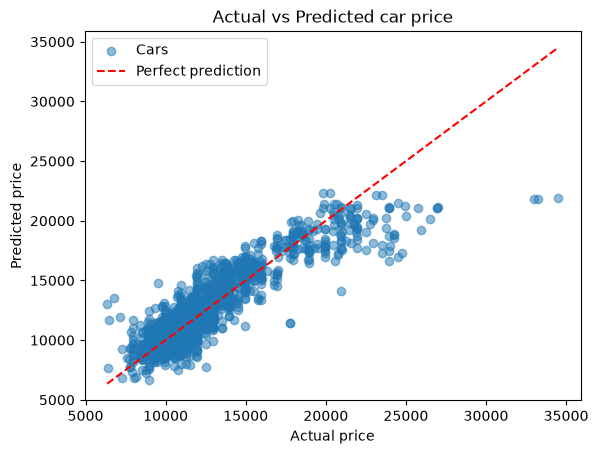

In [26]:
# Actual vs predicted
plt.scatter(y, y_pred, alpha=0.5, label="Cars")
plt.plot([y.min(), y.max()], [y.min(), y.max()], "r--", label="Perfect prediction")
plt.title("Actual vs Predicted car price")
plt.xlabel("Actual price")
plt.ylabel("Predicted price")
plt.legend()
plt.show()

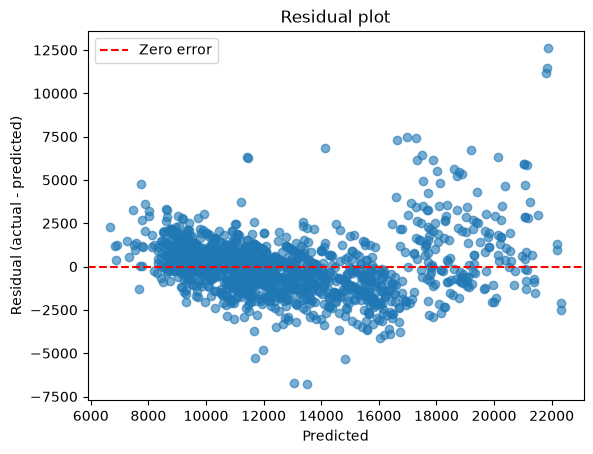

In [27]:
# Residual plot
residuals = y - y_pred
plt.scatter(y_pred, residuals, alpha=0.6)
plt.axhline(0, color="red", linestyle="--", label="Zero error")
plt.title("Residual plot")
plt.xlabel("Predicted")
plt.ylabel("Residual (actual - predicted)")
plt.legend()
plt.show()

### Q54

Consider a dataset HousePrices.csv with features such as size (in square feet) and a target column price (in dollars). Write a Python code to implement Linear Regression using Gradient Descent to predict price based on size. Use the complete dataset to train the model. Plot the regression line along with the training data points.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
# Size column is 'square_feet' (as in Q52); for house-prices.csv use 'SqFt' and 'Price'
df = pd.read_csv("datasets/HousePrices.csv")
x = df["square_feet"].values.astype(float)
y = df["price"].values.astype(float)

# Standardize x so gradient descent converges quickly
x_mean, x_std = x.mean(), x.std()
xs = (x - x_mean) / x_std

In [ ]:
# Gradient descent for y = m * xs + b (loss = MSE)
m, b = 0.0, 0.0
lr = 0.1
epochs = 1000
n = len(xs)
losses = []
for _ in range(epochs):
    y_hat = m * xs + b
    error = y_hat - y
    dm = (2 / n) * np.sum(error * xs)     # dLoss/dm
    db = (2 / n) * np.sum(error)          # dLoss/db
    m -= lr * dm
    b -= lr * db
    losses.append(np.mean(error ** 2))

# Convert slope back to original units
slope = m / x_std
intercept = b - m * x_mean / x_std
print(f"price = {slope:.2f} * square_feet + {intercept:.2f}")
print("Final MSE:", round(losses[-1], 2))

In [ ]:
# Loss curve
plt.plot(losses)
plt.title("Gradient Descent: MSE vs epochs")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.show()

In [ ]:
# Regression line with training data
x_line = np.linspace(x.min(), x.max(), 100)
plt.scatter(x, y, alpha=0.6, label="Training data")
plt.plot(x_line, slope * x_line + intercept, color="red", label="GD regression line")
plt.title("Linear Regression with Gradient Descent")
plt.xlabel("Size (square feet)")
plt.ylabel("Price ($)")
plt.legend()
plt.show()

### Q55

Consider a dataset CarPrices.csv with features such as horsepower, age, and a target column price. Write a Python code to fit a linear regression model to predict price based on the features and evaluate the model using MSE, R², and MAE.

In [33]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [34]:
# Use all features (age = 'months_old'); fuel_type is text -> one-hot
df = pd.read_csv("datasets/CarPrices.csv")
print(df.head())
X = pd.get_dummies(df.drop("price", axis=1), drop_first=True, dtype=int)
y = df["price"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

   months_old      km fuel_type  horsepower  metcolor  automatic  size_engine  \
0          73   97494    Petrol         110         1          0         1600   
1          48   89049    Petrol          97         1          0         1400   
2          40  161000    Diesel          69         1          0         1900   
3          37   38812    Petrol          97         0          0         1400   
4          55   33230    Petrol         110         0          0         1600   

   doors_num  weight  price  
0          5    1085  10950  
1          5    1060  13500  
2          3    1105  13950  
3          3    1025  13450  
4          3    1050  13500  


In [35]:
model = LinearRegression()
model.fit(X_train, y_train)
print("Coefficients:"); print(pd.Series(model.coef_, index=X.columns).round(3))

Coefficients:
months_old          -118.438
km                    -0.016
horsepower            48.058
metcolor              98.881
automatic            163.423
size_engine           -3.672
doors_num            -48.912
weight                23.323
fuel_type_Diesel    2702.737
fuel_type_Petrol    1272.442
dtype: float64


In [36]:
# Evaluate
y_pred = model.predict(X_test)
print("MAE:", round(mean_absolute_error(y_test, y_pred), 2))
print("MSE:", round(mean_squared_error(y_test, y_pred), 2))
print("R2: ", round(r2_score(y_test, y_pred), 4))

MAE: 932.1
MSE: 1774469.1
R2:  0.8614


### Q56

Consider a dataset HouseData.csv with features such as num_rooms, square_feet, and location, and a target column house_price. Write a Python code to fit a linear regression model to predict house_price based on the features and evaluate the model using Mean Squared Error (MSE), R², and Mean Absolute Error (MAE).

In [37]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [38]:
# Real columns: num_rooms -> 'Bedrooms', square_feet -> 'SqFt', location -> 'Neighborhood', house_price -> 'Price'
df = pd.read_csv("datasets/HouseData.csv")
print(df.head())
X = pd.get_dummies(df[["Bedrooms", "SqFt", "Neighborhood"]], drop_first=True, dtype=int)
y = df["Price"]
print(X.head())
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

   Home   Price  SqFt  Bedrooms  Bathrooms  Offers Brick Neighborhood
0     1  114300  1790         2          2       2    No         East
1     2  114200  2030         4          2       3    No         East
2     3  114800  1740         3          2       1    No         East
3     4   94700  1980         3          2       3    No         East
4     5  119800  2130         3          3       3    No         East
   Bedrooms  SqFt  Neighborhood_North  Neighborhood_West
0         2  1790                   0                  0
1         4  2030                   0                  0
2         3  1740                   0                  0
3         3  1980                   0                  0
4         3  2130                   0                  0


In [39]:
model = LinearRegression()
model.fit(X_train, y_train)
print("Coefficients:"); print(pd.Series(model.coef_, index=X.columns).round(2))

Coefficients:
Bedrooms               2197.37
SqFt                     45.70
Neighborhood_North   -12328.83
Neighborhood_West     30080.80
dtype: float64


In [40]:
# Evaluate
y_pred = model.predict(X_test)
print("MAE:", round(mean_absolute_error(y_test, y_pred), 2))
print("MSE:", round(mean_squared_error(y_test, y_pred), 2))
print("R2: ", round(r2_score(y_test, y_pred), 4))

MAE: 12598.91
MSE: 276452473.43
R2:  0.531


### Q57

Consider a dataset EmployeeData.csv with features such as years_of_experience, education_level, and a target column salary. Write a Python code to fit a linear regression model to predict salary based on the features and evaluate the model using Mean Squared Error (MSE), R-squared (R²), and Mean Absolute Error (MAE)

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
df = pd.read_csv("datasets/EmployeeData.csv")
df = df.dropna()
print(df.head())
print(df["education_level"].value_counts())

In [ ]:
# education_level is text -> one-hot columns
X = pd.get_dummies(df[["years_of_experience", "education_level"]], drop_first=True, dtype=int)
y = df["salary"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = LinearRegression()
model.fit(X_train, y_train)
print("Coefficients:"); print(pd.Series(model.coef_, index=X.columns).round(2))

In [ ]:
# Evaluate
y_pred = model.predict(X_test)
print("MAE:", round(mean_absolute_error(y_test, y_pred), 2))
print("MSE:", round(mean_squared_error(y_test, y_pred), 2))
print("R2: ", round(r2_score(y_test, y_pred), 4))

### Q58

Consider a dataset HousingData.csv with columns num_rooms, area, age, and a target column price. Write a Python code to fit a Lasso regression model using num_rooms, area, and age as independent variables to predict price. Use the complete dataset to train the model. Plot the coefficients of the features and create a residual plot.

In [45]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_squared_error, r2_score

In [46]:
# Real file has no 'age' column: num_rooms -> 'Bedrooms', area -> 'SqFt', third feature -> 'Bathrooms'
df = pd.read_csv("datasets/HousingData.csv")
print(df.head())
X = df[["Bedrooms", "SqFt", "Bathrooms"]]
y = df["Price"]

   Home   Price  SqFt  Bedrooms  Bathrooms  Offers Brick Neighborhood
0     1  114300  1790         2          2       2    No         East
1     2  114200  2030         4          2       3    No         East
2     3  114800  1740         3          2       1    No         East
3     4   94700  1980         3          2       3    No         East
4     5  119800  2130         3          3       3    No         East


In [47]:
# Scale features (fair penalty), fit on complete dataset
X = pd.DataFrame(StandardScaler().fit_transform(X), columns=X.columns)
model = Lasso(alpha=100)
model.fit(X, y)
y_pred = model.predict(X)
print("R2: ", round(r2_score(y, y_pred), 4))
print("MSE:", round(mean_squared_error(y, y_pred), 4))

R2:  0.4395
MSE: 401454710.1483


Bathrooms    6888.9991
SqFt         7466.2319
Bedrooms     7507.6211
dtype: float64


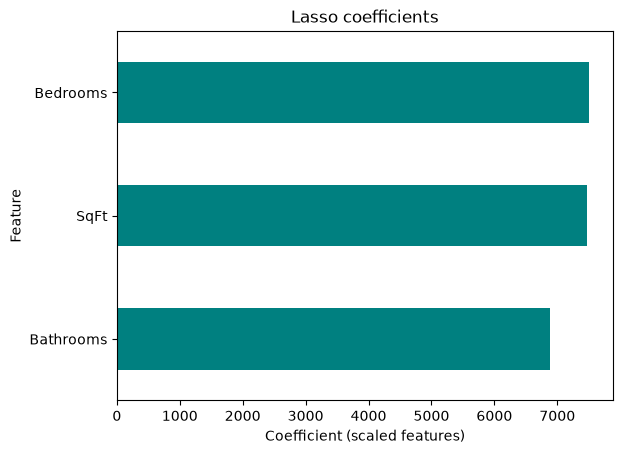

In [48]:
# Coefficient plot
coef = pd.Series(model.coef_, index=X.columns).sort_values()
print(coef.round(4))
coef.plot(kind="barh", color="teal")
plt.title("Lasso coefficients")
plt.xlabel("Coefficient (scaled features)")
plt.ylabel("Feature")
plt.show()

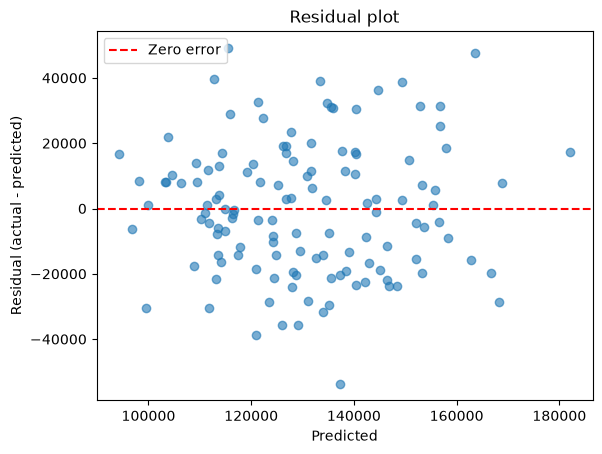

In [49]:
# Residual plot
residuals = y - y_pred
plt.scatter(y_pred, residuals, alpha=0.6)
plt.axhline(0, color="red", linestyle="--", label="Zero error")
plt.title("Residual plot")
plt.xlabel("Predicted")
plt.ylabel("Residual (actual - predicted)")
plt.legend()
plt.show()

### Q59

Consider a dataset Diabetes.csv with various medical attributes and a target column diabetes_progression. Write a Python code to fit a Ridge regression model using all available features to predict diabetes_progression. Use the complete dataset to train the model. Plot the coefficients of the features and create a residual plot.

In [50]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, r2_score

In [51]:
# Real Diabetes.csv (Pima) has no 'diabetes_progression'; its target column is 'Outcome'
# If the exam file has 'diabetes_progression', just change the target name below
target = "Outcome"
df = pd.read_csv("datasets/Diabetes.csv")
print(df.head())
X = df.drop(target, axis=1)
y = df[target]

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  


In [52]:
# Scale features (fair penalty), fit on complete dataset
X = pd.DataFrame(StandardScaler().fit_transform(X), columns=X.columns)
model = Ridge(alpha=1.0)
model.fit(X, y)
y_pred = model.predict(X)
print("R2: ", round(r2_score(y, y_pred), 4))
print("MSE:", round(mean_squared_error(y, y_pred), 4))

R2:  0.3033
MSE: 0.1583


BloodPressure              -0.0450
Insulin                    -0.0206
SkinThickness               0.0024
Age                         0.0309
DiabetesPedigreeFunction    0.0487
Pregnancies                 0.0692
BMI                         0.1042
Glucose                     0.1889
dtype: float64


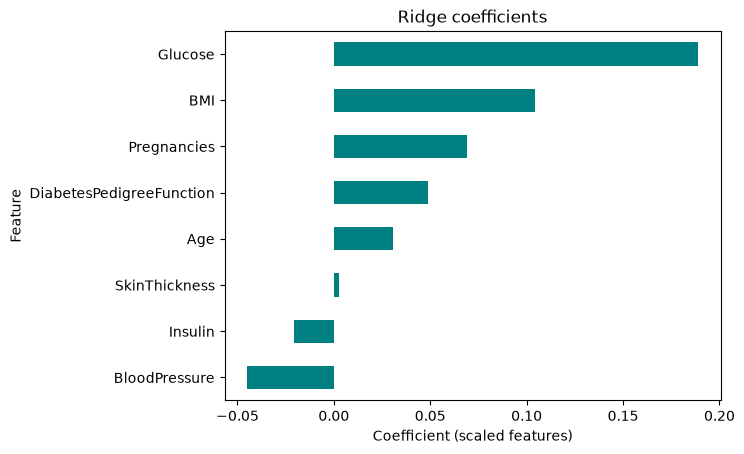

In [53]:
# Coefficient plot
coef = pd.Series(model.coef_, index=X.columns).sort_values()
print(coef.round(4))
coef.plot(kind="barh", color="teal")
plt.title("Ridge coefficients")
plt.xlabel("Coefficient (scaled features)")
plt.ylabel("Feature")
plt.show()

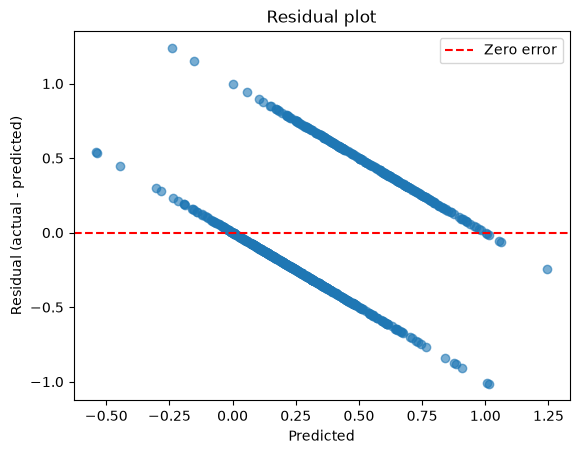

In [54]:
# Residual plot
residuals = y - y_pred
plt.scatter(y_pred, residuals, alpha=0.6)
plt.axhline(0, color="red", linestyle="--", label="Zero error")
plt.title("Residual plot")
plt.xlabel("Predicted")
plt.ylabel("Residual (actual - predicted)")
plt.legend()
plt.show()

### Q60

Consider a dataset WineQuality.csv with various chemical properties of wine and a target column quality. Write a Python code to fit a Lasso regression model using all available features to predict quality. Use the complete dataset to train the model. Plot the coefficients of the features and create a residual plot.

In [55]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_squared_error, r2_score

In [56]:
# Drop 'Id' (row number, not a feature)
df = pd.read_csv("datasets/WineQuality.csv")
print(df.head())
X = df.drop(["quality", "Id"], axis=1)
y = df["quality"]

   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  Id  
0      9.4        5   0  
1      9.8        5   1  
2      9

In [57]:
# Scale features (fair penalty), fit on complete dataset
X = pd.DataFrame(StandardScaler().fit_transform(X), columns=X.columns)
model = Lasso(alpha=0.01)
model.fit(X, y)
y_pred = model.predict(X)
print("R2: ", round(r2_score(y, y_pred), 4))
print("MSE:", round(mean_squared_error(y, y_pred), 4))

R2:  0.3719
MSE: 0.4075


volatile acidity       -0.1963
chlorides              -0.0688
total sulfur dioxide   -0.0672
pH                     -0.0581
residual sugar          0.0000
citric acid            -0.0000
free sulfur dioxide     0.0000
fixed acidity           0.0000
density                -0.0000
sulphates               0.1307
alcohol                 0.3128
dtype: float64


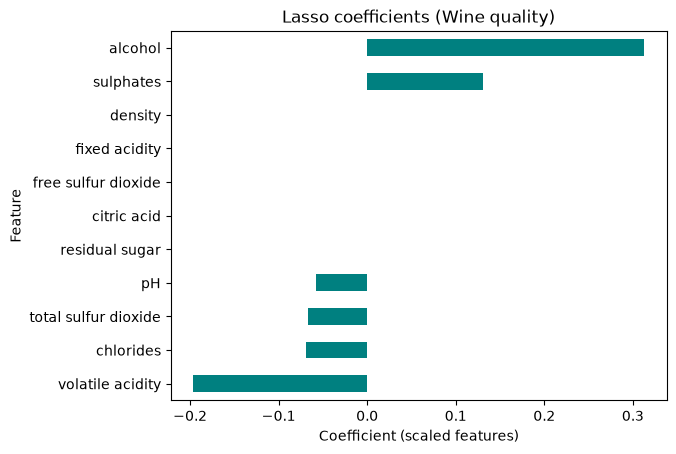

In [58]:
# Coefficient plot
coef = pd.Series(model.coef_, index=X.columns).sort_values()
print(coef.round(4))
coef.plot(kind="barh", color="teal")
plt.title("Lasso coefficients (Wine quality)")
plt.xlabel("Coefficient (scaled features)")
plt.ylabel("Feature")
plt.show()

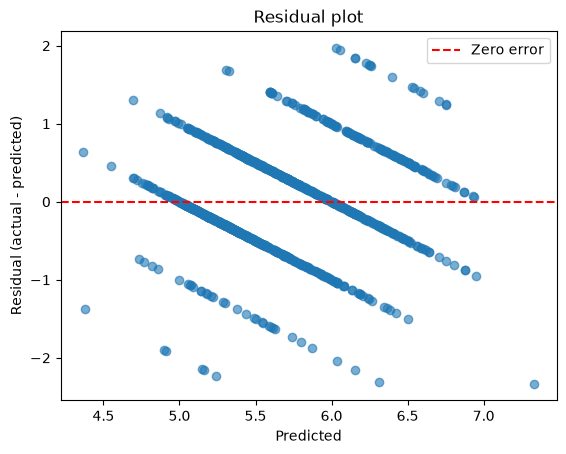

In [59]:
# Residual plot
residuals = y - y_pred
plt.scatter(y_pred, residuals, alpha=0.6)
plt.axhline(0, color="red", linestyle="--", label="Zero error")
plt.title("Residual plot")
plt.xlabel("Predicted")
plt.ylabel("Residual (actual - predicted)")
plt.legend()
plt.show()

### Q61

Consider a dataset HealthData.csv with features such as age, bmi, blood_pressure, and a target column health_score. Write a Python code to fit a Lasso regression model using all available features to predict health_score. Use the complete dataset to train the model. Plot the coefficients of the features and create a residual plot.

In [60]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_squared_error, r2_score

In [61]:
df = pd.read_csv("datasets/HealthData.csv")
print(df.head())
X = df.drop("health_score", axis=1)
y = df["health_score"]

   age   bmi  blood_pressure  health_score
0   56  39.8             116          69.3
1   69  21.5             144          85.8
2   46  29.6             122          84.8
3   32  37.4             157          65.4
4   60  34.4             175          58.9


In [62]:
# Scale features (fair penalty), fit on complete dataset
X = pd.DataFrame(StandardScaler().fit_transform(X), columns=X.columns)
model = Lasso(alpha=0.1)
model.fit(X, y)
y_pred = model.predict(X)
print("R2: ", round(r2_score(y, y_pred), 4))
print("MSE:", round(mean_squared_error(y, y_pred), 4))

R2:  0.9904
MSE: 1.3713


bmi              -9.0013
blood_pressure   -7.3125
age              -3.2966
dtype: float64


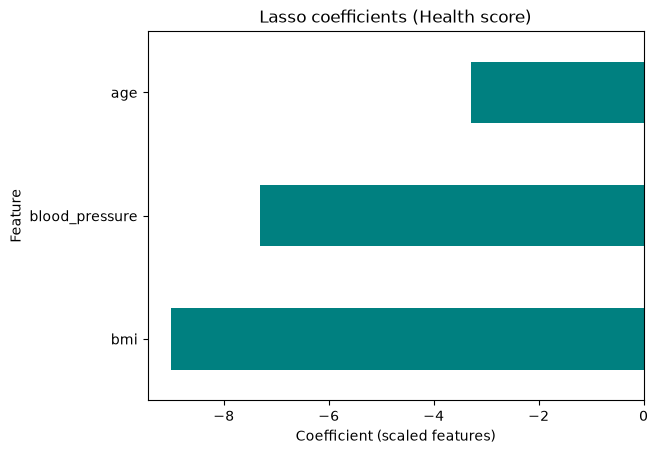

In [63]:
# Coefficient plot
coef = pd.Series(model.coef_, index=X.columns).sort_values()
print(coef.round(4))
coef.plot(kind="barh", color="teal")
plt.title("Lasso coefficients (Health score)")
plt.xlabel("Coefficient (scaled features)")
plt.ylabel("Feature")
plt.show()

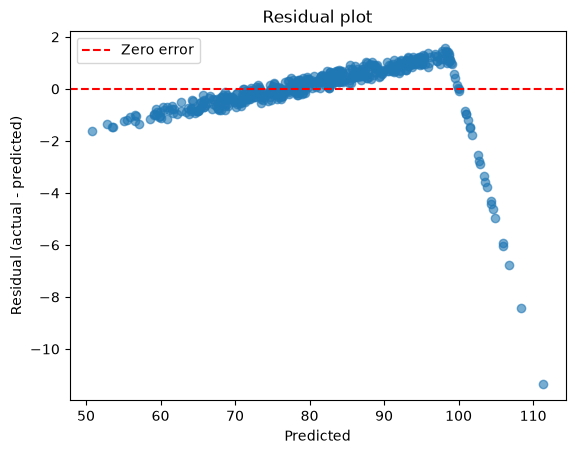

In [64]:
# Residual plot
residuals = y - y_pred
plt.scatter(y_pred, residuals, alpha=0.6)
plt.axhline(0, color="red", linestyle="--", label="Zero error")
plt.title("Residual plot")
plt.xlabel("Predicted")
plt.ylabel("Residual (actual - predicted)")
plt.legend()
plt.show()